<div data-bmll-brand="notebook-header" style="display:flex;justify-content:space-between;align-items:center;padding:0 0 12px;border-bottom:2px solid #146BC1;margin-bottom:18px;font-family:Exo,Inter,Helvetica,Arial,sans-serif;">
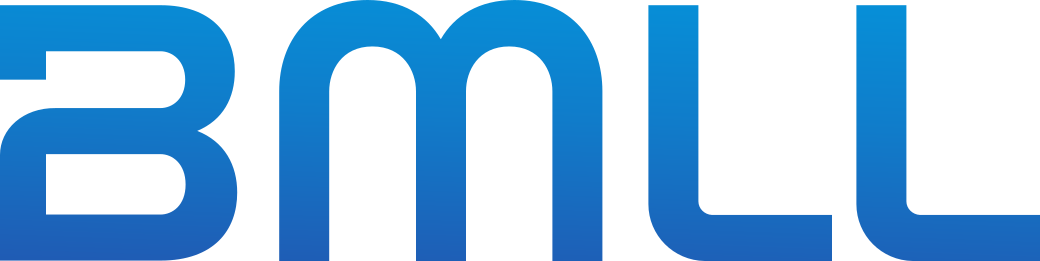
<span style="color:#878786;font-size:11px;"></span>
</div>


# Market State Analysis

Compare auction durations, trading schedules and interruptions with bmll.data.query.

**Environment:** BMLL Query API

In [2]:
# BMLL notebook style helpers. Generated from inputs/bmll-notebook-branding.
BMLL_COLOURS = {
    'primary': {'blue_1': '#333396', 'blue_2': '#146BC1', 'blue_3': '#009DDF'},
    'secondary': {
        'mauve': '#787BA7', 'grape': '#753C78', 'mint': '#5BACA1',
        'vanilla': '#F0D36E', 'tangerine': '#DE5F46', 'diesel': '#2E6195',
    },
    'tints': {
        'k_100': '#000000', 'k_80': '#575656', 'k_60': '#878786',
        'k_40': '#B3B2B2', 'k_20': '#DADADA', 'k_10': '#ECECEC',
    },
}
BMLL_PRIMARY_BLUE = BMLL_COLOURS['primary']['blue_2']
BMLL_CYCLE = [
    '#146BC1', '#DE5F46', '#5BACA1', '#753C78', '#F0D36E',
    '#2E6195', '#787BA7', '#333396', '#009DDF',
]
BMLL_SEQ_BLUE = [[0.0, '#E6F4FA'], [0.5, '#009DDF'], [1.0, '#333396']]
BMLL_SEQ_TANGERINE = [[0.0, '#FFF1ED'], [0.5, '#DE5F46'], [1.0, '#7C2614']]
BMLL_DIVERGING = [[0.0, '#DE5F46'], [0.5, '#F2F2F2'], [1.0, '#5BACA1']]

def add_bmll_source(fig):
    if not hasattr(fig, 'add_annotation'):
        return fig
    existing = getattr(fig.layout, 'annotations', None) or ()
    if any(getattr(a, 'name', None) == '_bmll_source' for a in existing):
        return fig
    fig.add_annotation(
        name='_bmll_source', xref='paper', yref='paper', x=1.0, y=0.0,
        xanchor='right', yanchor='top', yshift=-60, showarrow=False,
        text='Source: BMLL',
        font=dict(color=BMLL_PRIMARY_BLUE, size=11, family='Inter, Helvetica, Arial, sans-serif'),
    )
    return fig

def apply_bmll_plotly_style(fig, *, show_source=True):
    if hasattr(fig, 'update_layout'):
        fig.update_layout(
            font=dict(family='Inter, Helvetica, Arial, sans-serif', color='#1a1a1a'),
            colorway=BMLL_CYCLE,
            paper_bgcolor='white',
            plot_bgcolor='white',
            margin=dict(l=80, r=40, t=80, b=90),
        )
        fig.update_xaxes(showgrid=True, gridcolor='#ECECEC', zerolinecolor='#DADADA')
        fig.update_yaxes(showgrid=True, gridcolor='#ECECEC', zerolinecolor='#DADADA')
    if show_source:
        add_bmll_source(fig)
    return fig

try:
    import plotly.io as _pio
    _pio.templates['bmll'] = _pio.templates['plotly_white']
    _pio.templates['bmll'].layout.font = dict(family='Inter, Helvetica, Arial, sans-serif', color='#1a1a1a')
    _pio.templates['bmll'].layout.colorway = BMLL_CYCLE
    _pio.templates.default = 'bmll'
except Exception:
    pass

<div data-bmll-brand="section-header" style="display:flex;align-items:center;gap:10px;border-bottom:1px solid #DADADA;padding:6px 0 8px;margin:4px 0 10px;font-family:Exo,Inter,Helvetica,Arial,sans-serif;">
<span style="background:#146BC1;color:white;font-size:11px;font-weight:700;padding:2px 8px;border-radius:2px;letter-spacing:0.05em;">SECTION 1</span>
<span style="font-size:15px;font-weight:600;color:#1a1a1a;">Explore the trading day with market-state events</span>
</div>
When does continuous trading start? How long does the closing auction last?
Use BMLL's market-state events to compare auction durations, session timing and
unscheduled interruptions. This example follows AZN on XLON across two sessions.

In [4]:
import bmll.data
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

TICKER = "AZN"
MIC = "XLON"
DATES = ["2026-08-24", "2026-08-25"]
EXCHANGE_TIMEZONE = "Europe/London"

### 1. Load reference and market-state events
Resolve the listing for each date, then request its state changes. Keeping every
state lets us measure each interval through to its actual next transition.

In [6]:
if not DATES or len(set(DATES)) != len(DATES):
    raise ValueError("Choose distinct session dates")
sessions = []
for day in sorted(DATES):
    reference = bmll.data.query("reference", start_date=day, MIC=MIC,
                                Ticker=TICKER, columns=["ListingId"])
    listing_ids = reference["ListingId"].dropna().unique()
    if len(listing_ids) != 1:
        raise ValueError(f"Expected one listing for {TICKER} on {day}")
    events = bmll.data.query(
        "market_state", start_date=day, MIC=MIC, ListingId=str(listing_ids[0]),
        columns=["TradeDate", "ListingId", "TimestampNanoseconds", "BMLLSequenceNo", "MarketState"],
    )
    if events.empty:
        raise ValueError(f"No market-state events for {TICKER}/{MIC} on {day}")
    if not events["ListingId"].eq(listing_ids[0]).all() or not pd.to_datetime(events["TradeDate"]).dt.date.eq(pd.Timestamp(day).date()).all():
        raise ValueError("Returned events do not match the requested listing/session")
    sessions.append(events)
state_events = pd.concat(sessions, ignore_index=True)
del sessions, events
print(f"{len(state_events)} events for {TICKER}/{MIC} across {len(DATES)} sessions")
display(state_events.head())

18 events for AZN/XLON across 2 sessions


/home/bertrand/miniconda3/lib/python3.11/site-packages/bmll2/_internals/api/configure.py:116: UserWarning: BMLL configuration file (/tmp/.nb_extension_instance_vars.json) not found. BMLL data and S3 storage will not be reachable.
  warnings.warn(f"{msg} BMLL data and S3 storage will not be reachable.", UserWarning)


,TradeDate,ListingId,TimestampNanoseconds,BMLLSequenceNo,MarketState
0,2026-08-24,121216,1787552100011872451,2616897,CLOSED
1,2026-08-24,121216,1787554200029654389,2616979,OPENING_AUCTION
2,2026-08-24,121216,1787554819404074586,2771036,CONTINUOUS_TRADING
3,2026-08-24,121216,1787585400094647166,17081097,CLOSING_AUCTION
4,2026-08-24,121216,1787585725713989214,17416139,POST_TRADE


### 2. Turn transitions into durations
Sort by timestamp and sequence, combine consecutive reports of the same state,
and subtract the next transition's timestamp. An unobserved final endpoint stays
unknown. UTC instants give elapsed durations; exchange-local times let us compare
the trading schedule across daylight-saving changes.

In [8]:
def market_state_intervals(events, timezone):
    frame = events.copy()
    required = ["TradeDate", "ListingId", "TimestampNanoseconds", "BMLLSequenceNo", "MarketState"]
    if frame[required].isna().any().any():
        raise ValueError("Market-state identity, timestamps and state must be present")
    frame["TradeDate"] = pd.to_datetime(frame["TradeDate"]).dt.normalize()
    frame["event_timestamp"] = pd.to_datetime(frame["TimestampNanoseconds"].astype("int64"), unit="ns", utc=True)
    group = ["ListingId", "TradeDate"]
    order = group + ["event_timestamp", "BMLLSequenceNo"]
    frame = frame.sort_values(order, kind="stable").drop_duplicates(order + ["MarketState"])
    if frame.duplicated(order).any():
        raise ValueError("Conflicting states share a timestamp and sequence")
    previous = frame.groupby(group)["MarketState"].shift()
    frame = frame.loc[frame["MarketState"].ne(previous).fillna(True)].copy()
    frame["next_timestamp"] = frame.groupby(group)["event_timestamp"].shift(-1)
    frame["duration_seconds"] = (frame["next_timestamp"] - frame["event_timestamp"]).dt.total_seconds()
    # Equal-time transitions remain visible as entries, but do not provide a
    # positive duration observation for the duration statistics.
    frame["duration_seconds"] = frame["duration_seconds"].where(frame["duration_seconds"] > 0)
    local = frame["event_timestamp"].dt.tz_convert(timezone)
    frame["local_start"] = local
    frame["start_minutes"] = local.dt.hour * 60 + local.dt.minute + local.dt.second / 60 + local.dt.microsecond / 60_000_000
    frame["month"] = frame["TradeDate"].dt.to_period("M").astype(str)
    return frame.reset_index(drop=True)


intervals = market_state_intervals(state_events, EXCHANGE_TIMEZONE)
report_states = ["OPENING_AUCTION", "CONTINUOUS_TRADING", "CLOSING_AUCTION", "INTRADAY_AUCTION", "UNSCHEDULED_AUCTION"]
selected = intervals[intervals["MarketState"].isin(report_states)].copy()
if selected.empty or selected["duration_seconds"].notna().sum() == 0:
    raise ValueError("No measurable trading or auction intervals in the selected sessions")
display(selected[["TradeDate", "MarketState", "local_start", "duration_seconds"]])

,TradeDate,MarketState,local_start,duration_seconds
1,2026-08-24,OPENING_AUCTION,2026-08-24 07:50:00.029654389+01:00,619.374420
2,2026-08-24,CONTINUOUS_TRADING,2026-08-24 08:00:19.404074586+01:00,30580.690573
3,2026-08-24,CLOSING_AUCTION,2026-08-24 16:30:00.094647166+01:00,325.619342
7,2026-08-25,OPENING_AUCTION,2026-08-25 07:50:00.012917424+01:00,600.603656
8,2026-08-25,CONTINUOUS_TRADING,2026-08-25 08:00:00.616573273+01:00,30599.474823
9,2026-08-25,CLOSING_AUCTION,2026-08-25 16:30:00.091396651+01:00,316.538947


### 3. Compare opening and closing auctions
Summaries describe the selected listing and dates. Duration statistics use
observed positive intervals; entry counts include intervals with unknown ends.
Bars show individual auction durations on a shared scale, labelled in minutes
and seconds. Monthly statistics remain available in the summary table.

In [10]:
summary = selected.groupby(["month", "MarketState"], as_index=False).agg(
    sessions=("TradeDate", "nunique"), entries=("MarketState", "size"),
    measured_intervals=("duration_seconds", "count"),
    median_duration_seconds=("duration_seconds", "median"),
    mean_duration_seconds=("duration_seconds", "mean"),
    std_duration_seconds=("duration_seconds", "std"),
    p25_seconds=("duration_seconds", lambda s: s.quantile(0.25)),
    p75_seconds=("duration_seconds", lambda s: s.quantile(0.75)),
    median_start_minutes=("start_minutes", "median"),
)

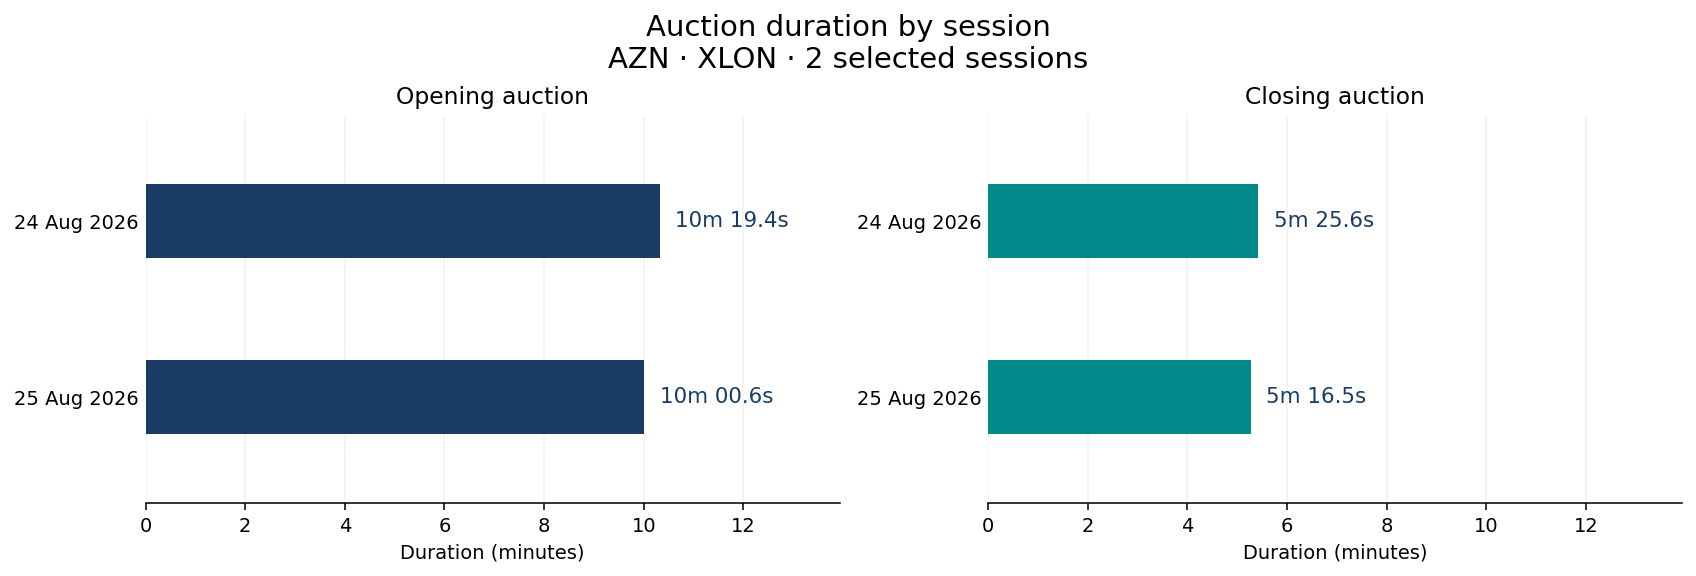

In [11]:
# Show the observations themselves: two sessions need two bars, not a monthly
# distribution. Keep the monthly statistics in the summary table below.
auction_data = selected[selected["MarketState"].isin(["OPENING_AUCTION", "CLOSING_AUCTION"])].copy()
longest = auction_data["duration_seconds"].max()
xmax = max(1, longest / 60 * 1.35) if pd.notna(longest) else 1
panel_rows = max(1, auction_data.groupby("MarketState").size().max()) if len(auction_data) else 1
fig, axes = plt.subplots(1, 2, figsize=(12, max(4, panel_rows * 0.55 + 2)), sharex=True, layout="constrained")
for ax, state, title, color in zip(axes, ["OPENING_AUCTION", "CLOSING_AUCTION"],
                                  ["Opening auction", "Closing auction"], ["#183C63", "#008B8B"]):
    data = auction_data[auction_data["MarketState"].eq(state)].sort_values("event_timestamp")
    if data.empty:
        ax.text(0.5, 0.5, "No auction entries observed", ha="center", transform=ax.transAxes)
        ax.set_yticks([])
    else:
        y = np.arange(len(data))
        labels = data["TradeDate"].dt.strftime("%d %b %Y")
        # Repeated auction entries on a date remain separate observations.
        if data["TradeDate"].duplicated(keep=False).any():
            labels = labels + " · " + data["local_start"].dt.strftime("%H:%M:%S")
        ax.barh(y, data["duration_seconds"] / 60, height=0.42, color=color)
        for row, seconds in enumerate(data["duration_seconds"]):
            if pd.notna(seconds):
                label = f"{int(seconds // 60)}m {seconds % 60:04.1f}s"
                ax.annotate(label, (seconds / 60, row), xytext=(8, 0), textcoords="offset points",
                            va="center", fontsize=11, color="#183C63")
            else:
                ax.text(xmax * 0.03, row, "End not observed", va="center", color="#666666")
        ax.set_yticks(y, labels)
        ax.set_ylim(len(data) - 0.4, -0.6)
    ax.set(title=title, xlabel="Duration (minutes)", xlim=(0, xmax))
    ax.grid(axis="x", alpha=0.15)
    ax.set_axisbelow(True)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(axis="y", length=0)
fig.suptitle(f"Auction duration by session\n{TICKER} · {MIC} · {len(DATES)} selected sessions", fontsize=15)
plt.show()

### 4. Check schedule consistency
Compare the first continuous-trading and closing-auction entries each day.
Using the first entry avoids counting restarts after interruptions as openings.
Dots show how many seconds each start differs from the median across the
selected sessions; labels give the actual local start time. Both panels use the
same scale, so small differences are not visually exaggerated.

In [13]:
schedule = selected[selected["MarketState"].isin(["CONTINUOUS_TRADING", "CLOSING_AUCTION"])].groupby(
    ["ListingId", "TradeDate", "MarketState"], sort=False).head(1)
schedule_summary = schedule.groupby(["month", "MarketState"], as_index=False).agg(
    observed_sessions=("TradeDate", "nunique"),
    median_start_minutes=("start_minutes", "median"),
    std_start_minutes=("start_minutes", "std"),
)

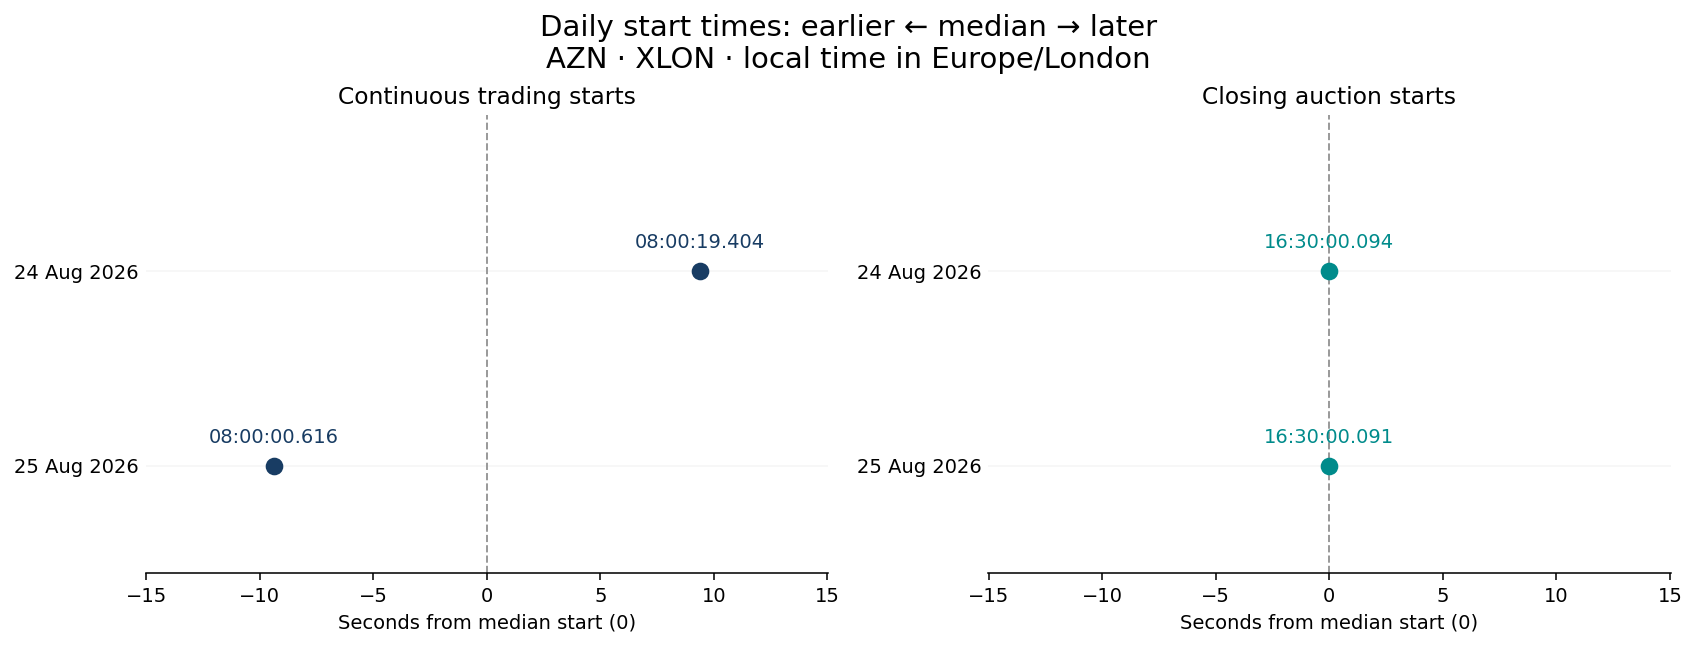

,month,MarketState,observed_sessions,median_start_minutes,std_start_minutes
0,2026-08,CLOSING_AUCTION,2,990.001550,0.000038
1,2026-08,CONTINUOUS_TRADING,2,480.166839,0.221413


In [14]:
schedule_plot = schedule.copy()
schedule_plot["offset_seconds"] = (
    schedule_plot["start_minutes"] - schedule_plot.groupby("MarketState")["start_minutes"].transform("median")
) * 60
largest_offset = schedule_plot["offset_seconds"].abs().max()
half_width = max(1, largest_offset * 1.6) if pd.notna(largest_offset) else 1
session_dates = pd.DatetimeIndex(sorted(DATES))
fig, axes = plt.subplots(1, 2, figsize=(12, max(4.5, len(DATES) * 0.65 + 2)), sharex=True, sharey=True, layout="constrained")
for ax, state, title, color in zip(axes, ["CONTINUOUS_TRADING", "CLOSING_AUCTION"],
                                  ["Continuous trading starts", "Closing auction starts"], ["#183C63", "#008B8B"]):
    data = schedule_plot[schedule_plot["MarketState"].eq(state)].set_index("TradeDate").reindex(session_dates)
    ax.axvline(0, color="#999999", linestyle="--", linewidth=1)
    ax.scatter(data["offset_seconds"], np.arange(len(data)), s=65, color=color, zorder=3)
    for row, (_, entry) in enumerate(data.iterrows()):
        if pd.notna(entry["local_start"]):
            label = entry["local_start"].strftime("%H:%M:%S.%f")[:-3]
            ax.annotate(label, (entry["offset_seconds"], row), xytext=(0, 12), textcoords="offset points",
                        ha="center", fontsize=10, color=color)
        else:
            ax.text(0, row, "Not observed", ha="center", color="#666666")
    ax.set_yticks(np.arange(len(session_dates)), session_dates.strftime("%d %b %Y"))
    ax.set(title=title, xlabel="Seconds from median start (0)", xlim=(-half_width, half_width))
    ax.set_ylim(len(session_dates) - 0.45, -0.8)
    ax.grid(axis="y", alpha=0.12)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(axis="y", length=0, labelleft=True)
fig.suptitle(f"Daily start times: earlier ← median → later\n{TICKER} · {MIC} · local time in {EXCHANGE_TIMEZONE}", fontsize=15)
plt.show()
display(schedule_summary)

### 5. Count unscheduled auctions
Count entries even when an auction's end is not observed. Sessions with no
unscheduled auctions are explicitly reported as zero. These counts describe the
selected listing, rather than all securities on the venue.

In [16]:
counts = intervals[intervals["MarketState"].eq("UNSCHEDULED_AUCTION")].groupby("TradeDate").size()
counts = counts.reindex(pd.DatetimeIndex(sorted(DATES)), fill_value=0)

Unscheduled-auction entries: 0


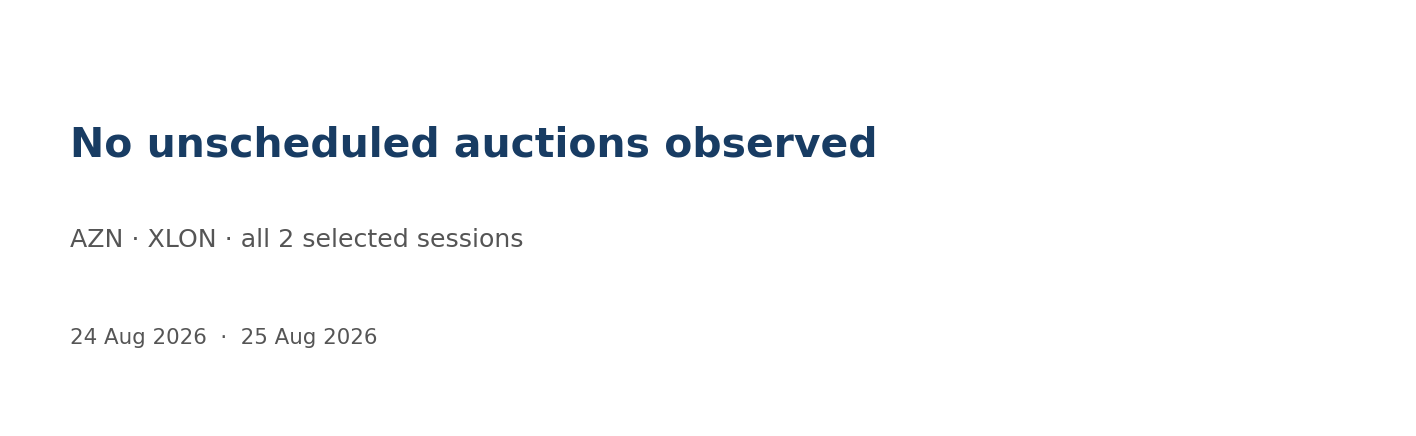

,month,MarketState,sessions,entries,measured_intervals,median_duration_seconds,mean_duration_seconds,std_duration_seconds,p25_seconds,p75_seconds,median_start_minutes
0,2026-08,CLOSING_AUCTION,2,2,2,321.079144,321.079144,6.420809,318.809046,323.349243,990.001550
1,2026-08,CONTINUOUS_TRADING,2,2,2,30590.082698,30590.082698,13.282471,30585.386635,30594.778761,480.166839
2,2026-08,OPENING_AUCTION,2,2,2,609.989038,609.989038,13.272935,605.296347,614.681729,470.000355


In [17]:
fig, ax = plt.subplots(figsize=(10, max(3, len(counts) * 0.45 + 1.7)), layout="constrained")
if counts.sum() == 0:
    ax.axis("off")
    ax.text(0.04, 0.65, "No unscheduled auctions observed", fontsize=21, weight="bold", color="#183C63", transform=ax.transAxes)
    ax.text(0.04, 0.43, f"{TICKER} · {MIC} · all {len(counts)} selected sessions", fontsize=13, color="#555555", transform=ax.transAxes)
    dates_label = "\n".join("  ·  ".join(counts.index[i:i + 4].strftime("%d %b %Y")) for i in range(0, len(counts), 4))
    ax.text(0.04, 0.23, dates_label, fontsize=11, color="#555555", va="top", transform=ax.transAxes)
else:
    from matplotlib.ticker import MaxNLocator
    ax.barh(np.arange(len(counts)), counts.to_numpy(), height=0.45, color="#183C63")
    for row, count in enumerate(counts):
        ax.annotate(str(count), (count, row), xytext=(8, 0), textcoords="offset points", va="center", fontsize=11)
    ax.set_yticks(np.arange(len(counts)), counts.index.strftime("%d %b %Y"))
    ax.invert_yaxis()
    ax.set(title=f"Unscheduled-auction entries by session — {TICKER} · {MIC}", xlabel="Number of entries", xlim=(0, counts.max() * 1.2 + 1))
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(axis="y", length=0)
plt.show()
print(f"Unscheduled-auction entries: {counts.sum()}")
display(summary)
result_df = summary